In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(100) # Setting seed for reproducibility

df = pd.read_csv("Accredian_dataset.csv") # Loading the data
print("Dataset is loaded successfully.")

Dataset is loaded successfully.


In [2]:
# Checking the dataset
df.head()
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


# Step-1: EDA (Exploratory Data Analysis)

In [3]:
# Checking Missing-values and Summary statistics
print("\033[1mMISSING VALUES\033[0m")
print(df.isnull().sum())

print("\033[1mSUMMARY STATISTICS\033[0m")
display(df.describe())

MISSING VALUES
batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
dtype: int64
SUMMARY STATISTICS


,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


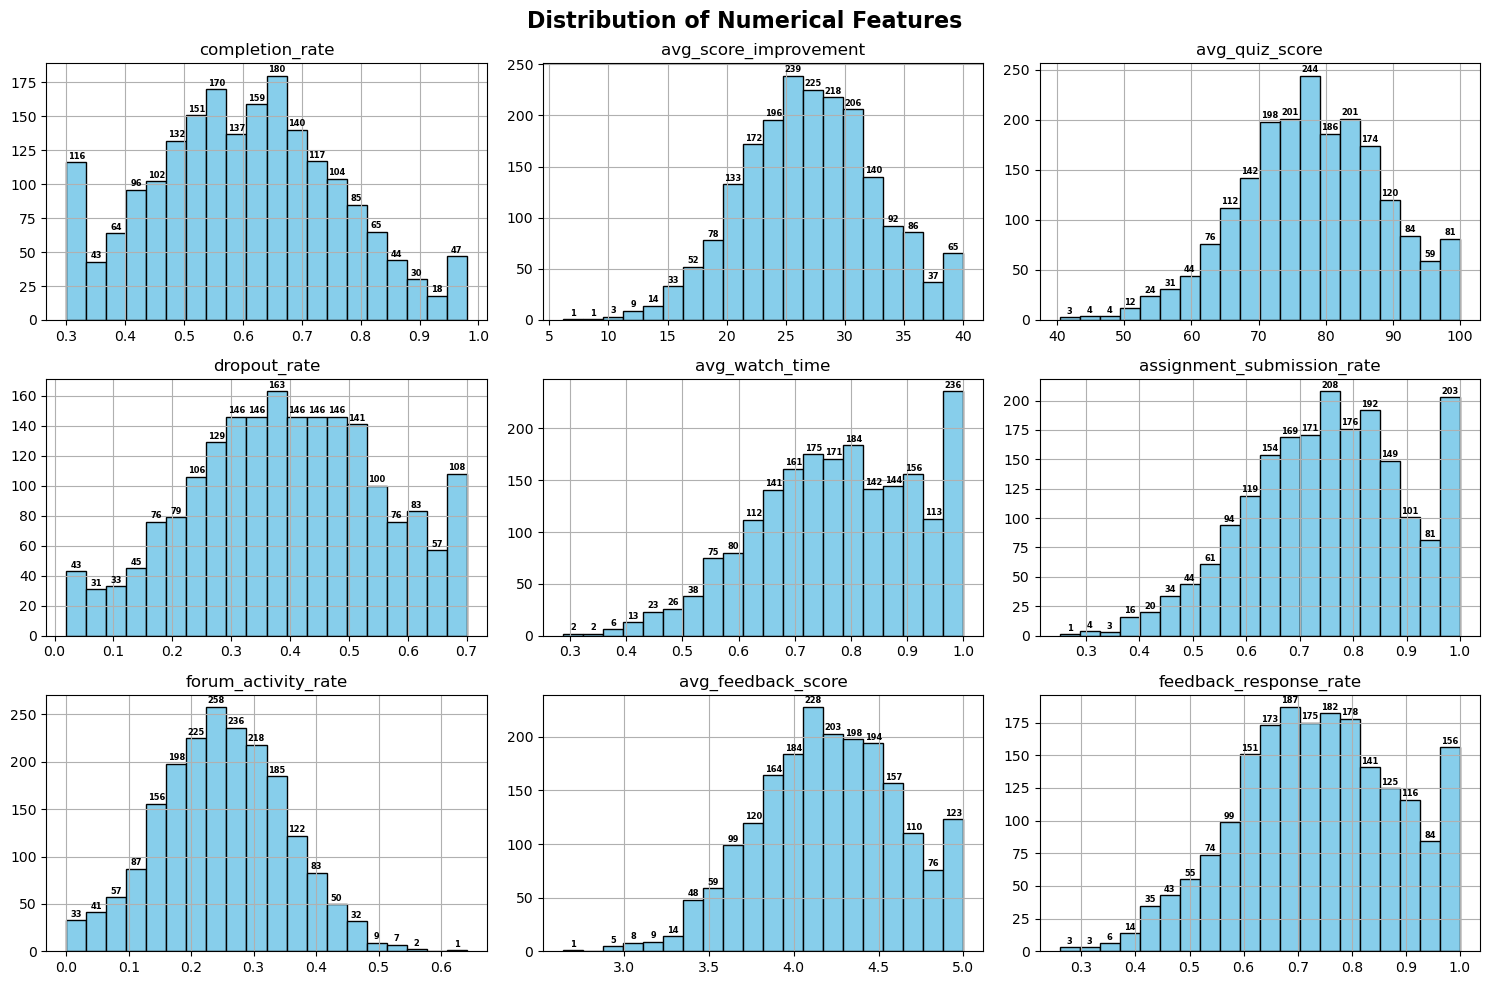

In [4]:
# Plotting Histogram to explore variable distributions
num_cols = [c for c in df.columns if c not in ['batch_id', 'course_id', 'instructor_id']]
axes = df[num_cols].hist(figsize = (15, 10), bins = 20, edgecolor = 'black', color = 'skyblue')
# Add data labels to each histogram bar
for ax in axes.flatten():
    for patch in ax.patches:
        height = patch.get_height()
        if height > 0:
            ax.annotate(f'{int(height)}',(patch.get_x() + patch.get_width() / 2., height),
                ha='center', va='bottom', fontsize=6, color='black', fontweight = 'bold',
                xytext=(0, 1), textcoords='offset points')
plt.suptitle('Distribution of Numerical Features', fontsize = 16, fontweight = 'bold')
plt.tight_layout()
plt.show()

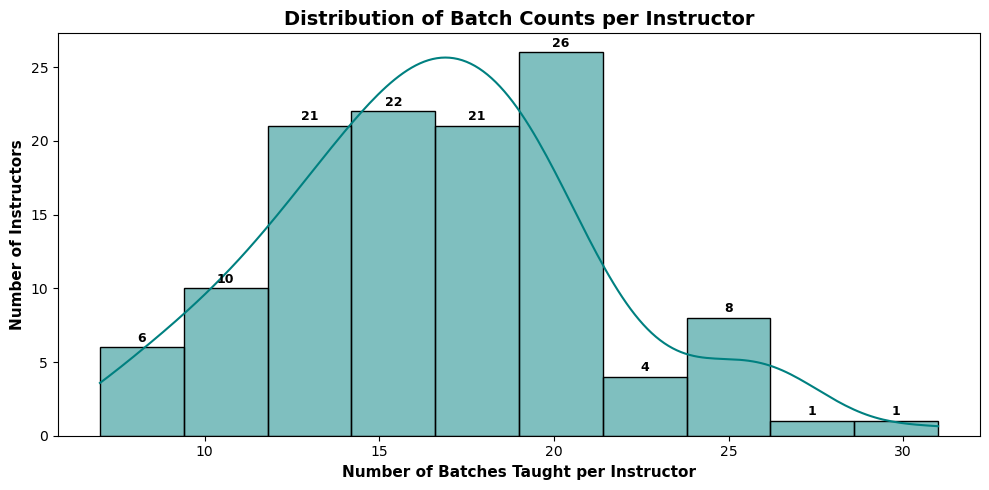

In [5]:
# Distrution of batches per instructor using Histogram plot
instructor_counts = df['instructor_id'].value_counts()

plt.figure(figsize=(10, 5))
ax = sns.histplot(instructor_counts, bins=10, kde=True, color='teal', edgecolor='black')

# Add bold data labels on top of the histogram bins
for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}', (patch.get_x() + patch.get_width() / 2., height), ha='center', va='bottom', fontsize=9, fontweight='bold',
                    color='black', xytext=(0, 2), textcoords='offset points')

plt.title('Distribution of Batch Counts per Instructor', fontsize=14, fontweight='bold')
plt.xlabel('Number of Batches Taught per Instructor', fontsize=11, fontweight='bold')
plt.ylabel('Number of Instructors', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

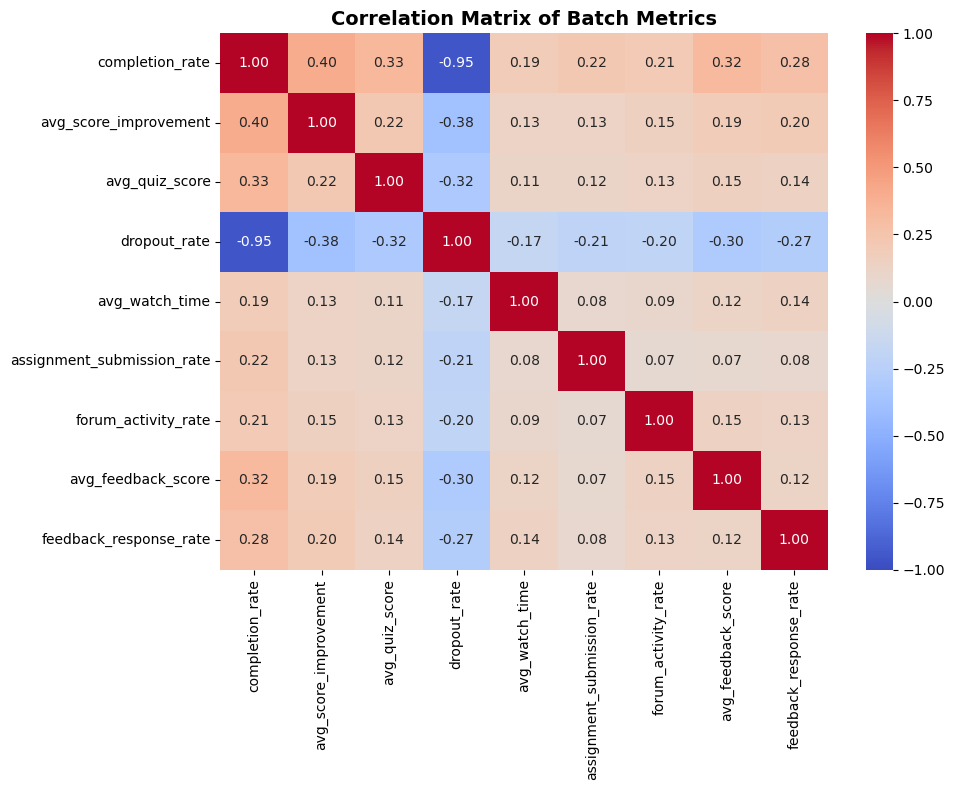

In [6]:
# Correlation Heatmap to explore relationships between variables
plt.figure(figsize = (10, 8))
sns.heatmap(df[num_cols].corr(), annot = True, fmt = '.2f', cmap = 'coolwarm', vmin = -1, vmax = 1)
plt.title('Correlation Matrix of Batch Metrics', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

Outlier Count Per Feature (IQR Method)
completion_rate: 0 potential outliers
dropout_rate: 0 potential outliers
assignment_submission_rate: 6 potential outliers
forum_activity_rate: 5 potential outliers
avg_feedback_score: 11 potential outliers
feedback_response_rate: 5 potential outliers
avg_score_improvement: 6 potential outliers
avg_quiz_score: 11 potential outliers
avg_watch_time: 3 potential outliers


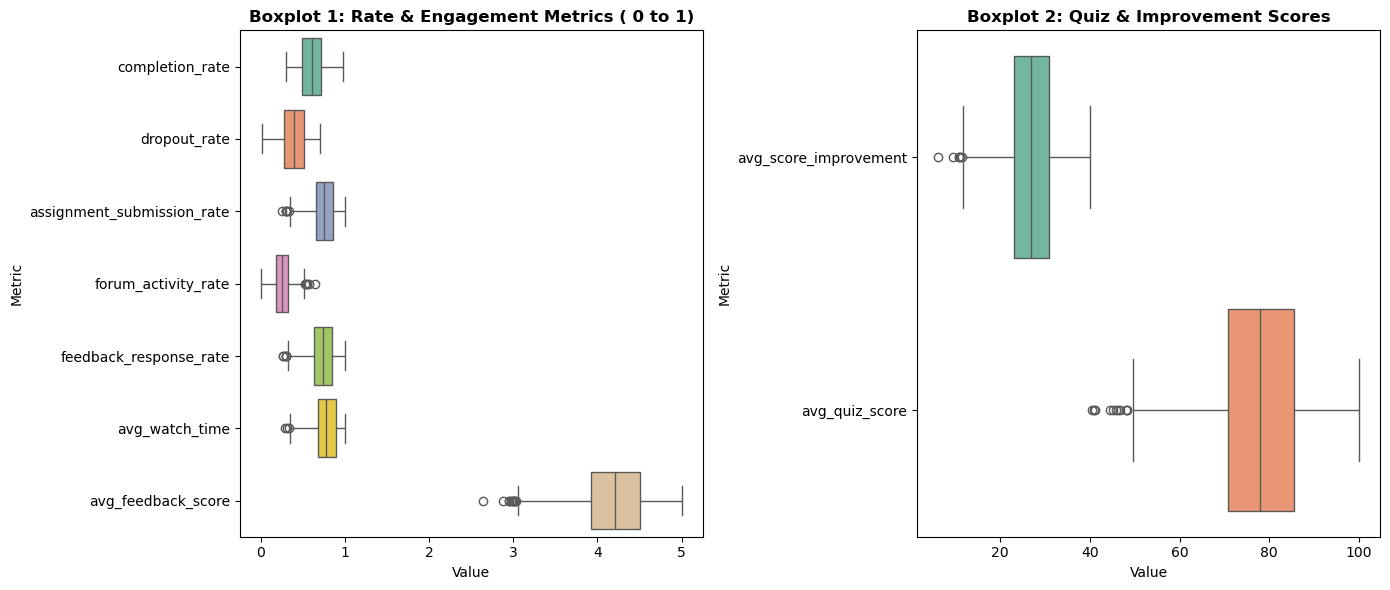

In [7]:
# Identify outliers using IQR across numerical features
num_cols = ['completion_rate', 'dropout_rate', 'assignment_submission_rate', 'forum_activity_rate', 'avg_feedback_score',
             'feedback_response_rate', 'avg_score_improvement', 'avg_quiz_score', 'avg_watch_time']
print("\033[1mOutlier Count Per Feature (IQR Method)\033[0m")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col}: {len(outliers)} potential outliers")



# Visualization by Boxplot

# Separate features by scale range
rate_cols = ['completion_rate', 'dropout_rate', 'assignment_submission_rate', 'forum_activity_rate', 'feedback_response_rate',
            'avg_watch_time', 'avg_feedback_score']
score_cols = ['avg_score_improvement', 'avg_quiz_score']

fig, axes = plt.subplots(1, 2, figsize = (14, 6))

# plot-1: metrics on 0-1 scale
df_rates = df[rate_cols].melt(var_name = 'Metric', value_name = 'Value')
sns.boxplot(data = df_rates, x = 'Value', y = 'Metric', hue = 'Metric', palette= 'Set2', legend = False, ax = axes[0])
axes[0].set_title('Boxplot 1: Rate & Engagement Metrics ( 0 to 1)', fontweight = 'bold', fontsize = 12)

# plot-2: metrics on Score scale
df_scores = df[score_cols].melt(var_name = 'Metric', value_name = 'Value')
sns.boxplot(data = df_scores, x = 'Value', y = 'Metric', hue = 'Metric', palette= 'Set2', legend = False, ax = axes[1])
axes[1].set_title('Boxplot 2: Quiz & Improvement Scores', fontweight = 'bold', fontsize = 12)

plt.tight_layout()
plt.show()

## Step-1 INSIGHTS: Exploratory Data Analysis (EDA)

1. The dataset contains 2,000 batch records and 12 columns (9 numerical and 3 categorical) with zero missing values across all columns.
2. All rate metrics strictly fall with the (0,1) inte4rval while "avg_feedback_score" lies between 2.64 & 5 with mean of 4.21 for having range 1 to 5
3. Almost all nine histograms show significantly skewed distributions. Majorly i.e., "avg_score_improvement", "avg_quiz_score", "avg_watch_time", "assignment_submission_rate", "avg_feedback_score", "feedback_response_rate" are left-skewed which are showing high concentration of ibservation on the high end.
4. "completion_rate", "avg_score_improvement" and "avg_quiz_score" follow symmetric Gaussian like distribution.
5. From **Summary Statistics** table, "completion_rate" (mean ~ 0.603) and "dropout_rate" (mean ~ 0.395) sum perfectly to 1.00 across all distribution quantiles, indicating **"dropout_rate"** and **"completion_rate"** has **near-perfect negative correlation**. From the **correlation Heatmap** visual this indication is proving i.e., **"completion_rate" and "dropout_rate" display an strong inverse correlation (r = -0.95)**.
6. "completion_rate" shows positive correlations with "avg_score_improvement" (r = 0.40), "avg_quiz_score" (r = 0.33), and "avg_feedback_score" (r = 0.32) which indicates higher completion directly coincides with stronger academic growth and learner satisfaction. Metrics such as "assignment_submission_rate" (r = 0.22) and "forum_activity_rate" (r = 0.21) show positive associations with "completion rates" as well, though "forum_activity_rate" remains low overall (mean ~ 0.25).
7. **Most instructors have managed between 10 and 20 batches (peaking around 20 batches), though a few outliers have taught as few as 6 or as many as 30 batches**.
8. **Interquartile Range (IQR) analysis indicates minimal severe outliers (e.g., 11 potential outliers in "avg_feedback_score" and "avg_quiz_score"), demonstrating stable data collection across batches**.
9. From Boxplot _
    I. Core engagement metrics like "completion_rate", "dropout_rate", and "assignment_submission_rate" display tight interquartile ranges (IQRs)   centered closely around their medians. This indicates consistent platform-wide performance across most course batches.
   II. For metrics such as "avg_quiz_score", "avg_score_improvement", "avg_watch_time", and "avg_feedback_score", all detected outliers lie strictly on the lower end (left-tailed). This highlights specific underperforming outlier batches that drag down overall scores.
   III. The box plot for "forum_activity_rate" sits extremely close to zero, with its upper whisker and outliers extending toward higher values. This confirms that high forum participation is rare and restricted to a few highly active batches.
   IV. The IQR for "avg_feedback_score" is heavily concentrated between 4.0 and 5.0, with a median well above 4.0. This indicates potential rating inflation or positive feedback bias across learners.

### Highlighting early observations _
i) As "completion_rate" and "dropout_rate" are almost perfectly inversely correlated, one of them (or a composite net metric) should be prioritised during feature engineering to avoid multicollinearity.
ii) Since batch counts per instructor vary (6 to 30 batches), instructors with low batch counts may show higher sample noise. The distribution should be weighted by batch volume or paired with standard deviation metrics to capture consistency. 
iii) Differing feature scales (percentage vs. 1-5 rating vs. 0-1 rating) necessitate Min-Max scaling prior to feature composite scoring.

# Step-2: Define Instructor Effectiveness 

## Definition and Composite Formula:

To quantify instructor performance across diverse course batches, we define a standardized **Instructor Effectiveness Score (IES)**. Since raw metrics operate on different scales (e.g., rates from 0 to 1, quiz scores from 0 to 100, and ratings from 1 to 5), and since courses differ in difficulty, every metric is **z-scored within its own course** before aggregation. A batch is therefore compared only with other batches of the same course.

---

## High-Level Composite Equation

$$IES = 0.40 \times Outcomes + 0.30 \times Engagement + 0.30 \times Feedback$$

Where each component pillar is defined as (all terms are within-course z-scores, denoted by the subscript *z*):

1. **Learner Outcomes Pillar (40% Weight)**

$$Outcomes = 0.50 \cdot completion\_rate_z + 0.25 \cdot avg\_score\_improvement_z + 0.25 \cdot avg\_quiz\_score_z$$

2. **Learner Engagement Pillar (30% Weight)**

$$Engagement = 0.40 \cdot avg\_watch\_time_z + 0.40 \cdot assignment\_submission\_rate_z + 0.20 \cdot forum\_activity\_rate_z$$

3. **Learner Feedback Pillar (30% Weight)**

$$Feedback = 0.70 \cdot avg\_feedback\_score_z + 0.30 \cdot feedback\_response\_rate_z$$

---

## Leakage-Free Label Construction

Each instructor's batches are randomly split into two halves (fixed seed = 42):

- **Half 0 (label half):** used **only** to compute the instructor's IES and tier.
- **Half 1 (feature half):** used **only** to build the model's input features (Step-3).

This ensures the model must predict the tier from *different batches* than those that defined it. It cannot simply re-learn the IES formula.

**Small-sample shrinkage:** each instructor's mean IES is shrunk toward the global mean:

$$IES_{shrunk} = \frac{n \cdot IES_{mean} + K \cdot IES_{global}}{n + K}, \quad K = 5$$

Instructors with few batches (6 to 8 in this dataset) are therefore pulled toward the average and are not over-ranked or over-penalised by a handful of batches.

---

## Effectiveness Tier Segmentation

Instructors are assigned to discrete performance tiers based on empirical percentile cutoffs of the shrunk IES:

- **Low Tier:** Below the 25th percentile (< P25): instructors requiring coaching, course redesign, or structural support.
- **Medium Tier:** 25th to 75th percentile (P25 to P75): instructors operating reliably at platform baseline standards.
- **High Tier:** Above the 75th percentile (> P75): benchmark instructors suitable for high-priority batches or mentoring programs.

*Note: tiers are relative by construction, so some instructors will always fall in the Low tier.*

## Justification & Underlying Assumptions:

**1. Strategic Pillar Weighting (40% / 30% / 30%)**

- **Outcomes Priority (40%):** The primary goal of an EdTech platform is skill acquisition and course completion. `completion_rate` carries the heaviest weight (20% overall) because retention directly correlates with educational impact and business success.
- **Balanced Engagement & Feedback (30% each):** Active participation (`assignment_submission_rate` and `avg_watch_time`) reflects the instructor's ability to keep learners motivated. Qualitative ratings capture student satisfaction, but `feedback_response_rate` is included to prevent skewed scores from low-response batches.

**2. Handling Multicollinearity & Redundancy**
`dropout_rate` was excluded from the calculation because it has a near-perfect negative correlation (r = -0.95) with `completion_rate` (the two sum to about 1 by design). Removing it avoids double-counting the same information.

**3. Controlling for Course Difficulty**
Metrics are z-scored within each course, so an instructor teaching a harder course (lower baseline completion or quiz scores) is not penalised relative to instructors of easier courses.

**4. Adjusting for Variable Baselines**
`forum_activity_rate` receives a reduced sub-weight (0.20) within the Engagement pillar because EDA showed universally low participation across all batches (mean about 0.25), so it discriminates less between instructors.

**5. Percentile-Based Tiering Rationale**
Dynamic percentiles (P25, P75) are used rather than fixed numerical thresholds to give a balanced class distribution (about 25% Low, 50% Medium, 25% High), which is suitable for model training. Because of this, the class balance is artificial and tiers are relative rankings, not absolute quality judgements.

**6. Small-Sample Shrinkage**
An instructor's mean score based on only a few batches is unreliable. Shrinking it toward the global mean, with strength K = 5, reduces the influence of a single unusual batch.

**7. Testing the Weight Choice**
The 40/30/30 weights are a judgement call, not a fact. To test how much they matter, the tiers are recomputed under three alternative weightings (equal weights, outcomes-heavy 60/20/20, and no feedback 50/50/0), and the share of instructors who keep the same tier is compared (results shown in the output below and in the summary).

In [8]:
# COURSE-ADJUSTED BATCH SCORE
# Z-score each metric WITHIN its course (so course difficulty doesn't bias instructors)
metrics = ["completion_rate", "avg_score_improvement", "avg_quiz_score",
           "avg_watch_time", "assignment_submission_rate", "forum_activity_rate",
           "avg_feedback_score", "feedback_response_rate"]   # dropout_rate excluded (redundant)

for m in metrics:
    g = df.groupby("course_id")[m]
    df[m + "_z"] = ((df[m] - g.transform("mean")) / g.transform("std")).fillna(0)

def compute_ies(d, w_out=0.40, w_eng=0.30, w_fb=0.30):
    """Instructor Effectiveness Score for batch rows (same pillar weights as before)."""
    outcomes   = 0.50*d["completion_rate_z"] + 0.25*d["avg_score_improvement_z"] + 0.25*d["avg_quiz_score_z"]
    engagement = 0.40*d["avg_watch_time_z"] + 0.40*d["assignment_submission_rate_z"] + 0.20*d["forum_activity_rate_z"]
    feedback   = 0.70*d["avg_feedback_score_z"] + 0.30*d["feedback_response_rate_z"]
    return w_out*outcomes + w_eng*engagement + w_fb*feedback

df["IES_batch"] = compute_ies(df)
print("Batch-level IES computed:", df["IES_batch"].describe().round(3).to_dict())

Batch-level IES computed: {'count': 2000.0, 'mean': -0.0, 'std': 0.545, 'min': -1.967, '25%': -0.374, '50%': 0.014, '75%': 0.358, 'max': 1.516}


In [9]:
# SPLIT EACH INSTRUCTOR'S BATCHES IN TWO HALVES (reproducible)
df = df.sort_values("batch_id").reset_index(drop=True)          # fixed starting order
df = df.sample(frac=1, random_state=42).reset_index(drop=True)  # same shuffle every time
df["half"] = df.groupby("instructor_id").cumcount() % 2
label_df = df[df["half"] == 0].copy()   # builds the tier
feat_df  = df[df["half"] == 1].copy()   # builds the features
print("Label-half batches:", len(label_df), "| Feature-half batches:", len(feat_df))

Label-half batches: 1032 | Feature-half batches: 968


In [10]:
# SHRUNK SCORE & TIERS
K = 5  # shrinkage strength: instructors with few batches are pulled toward the global mean

def make_labels(weights, K=K):
    s = compute_ies(label_df, *weights)
    tmp = pd.DataFrame({"iid": label_df["instructor_id"], "s": s})
    lab = tmp.groupby("iid")["s"].agg(n_label="count", ies_raw="mean")
    gm = s.mean()
    lab["IES_shrunk"] = (lab["n_label"]*lab["ies_raw"] + K*gm) / (lab["n_label"] + K)
    p25, p75 = lab["IES_shrunk"].quantile([0.25, 0.75])
    lab["effectiveness_tier"] = pd.cut(lab["IES_shrunk"], [-np.inf, p25, p75, np.inf],
                                       labels=["Low", "Medium", "High"]).astype(str)
    return lab

lab = make_labels((0.40, 0.30, 0.30))
print(lab["effectiveness_tier"].value_counts())

# Sensitivity: how many instructors keep the same tier under other weightings?
alt_weights = {"equal (1/3 each)": (1/3, 1/3, 1/3),
               "outcomes-heavy": (0.60, 0.20, 0.20),
               "no feedback": (0.50, 0.50, 0.00)}
for name, w in alt_weights.items():
    alt = make_labels(w)
    same = (alt["effectiveness_tier"] == lab["effectiveness_tier"]).mean()
    print(f"{name}: {same:.0%} of instructors keep the same tier")

print("P25 =", round(lab["IES_shrunk"].quantile(0.25), 4), "| P75 =", round(lab["IES_shrunk"].quantile(0.75), 4))

effectiveness_tier
Medium    60
High      30
Low       30
Name: count, dtype: int64
equal (1/3 each): 98% of instructors keep the same tier
outcomes-heavy: 97% of instructors keep the same tier
no feedback: 92% of instructors keep the same tier
P25 = -0.1718 | P75 = 0.1722


### Summary of Step-2:

1. **Course-adjusted batch score:** Each metric was z-scored within its own course, so course difficulty does not bias an instructor's score. `dropout_rate` was excluded because it is redundant with `completion_rate` (they sum to about 1). The batch-level IES uses the same pillar weights as before: Outcomes 40%, Engagement 30%, Feedback 30%.
2. **Leakage-free design:** Each instructor's batches were randomly split in two halves (seed = 42). Half 0 (1,032 batches) is used only to build the label (tier). Half 1 (968 batches) is used only to build the model features. The model therefore cannot simply re-learn the IES formula.
3. **Small-sample handling:** Instructor scores were shrunk toward the global mean with `K = 5`, so instructors with few batches (6 to 8 in this data) are not over-ranked or over-penalised.
4. **Tier distribution:** Percentile cut-offs on the shrunk IES (P25 = -0.1718, P75 = 0.1722) gave Medium = 60, High = 30 and Low = 30 out of 120 instructors. This matches the intended 25% / 50% / 25% split. IES values are centred near zero because metrics are z-scored within each course. Tiers are relative by construction, so someone is always "Low".
5. **Sensitivity to weights:** Tiers stayed the same for 98% of instructors under equal weights, 97% under outcomes-heavy weights (60/20/20), and 92% when feedback was removed (50/50/0). The tiering is therefore stable and does not depend heavily on the chosen weights.

# Step-3: Aggregate Batch Data to Instructor Level 

## Explaining Feature Aggregation & Instructor-Level Dataset Construction:

### Aggregation Strategy & Rationale

Features are built **only from the feature half** of each instructor's batches (968 of the 2,000 batches). The other half was used in Step-2 to build the tier label, so the model never sees the data that defined its target. All metrics are the within-course z-scores from Step-2. Aggregating them to the instructor level captures both **central tendency** (typical performance) and **variability** (consistency across batches):

1. **Mean:** Captures the expected baseline performance across the instructor's batches.
2. **Standard Deviation:** Captures consistency. A high mean paired with a high standard deviation indicates an erratic instructor, whereas a low standard deviation indicates stable performance across different learner cohorts.
3. **Batch Count (`n_batches_feat`):** Number of batches in the feature half. It tells the model how much evidence sits behind each instructor's mean and std.

### Handling Instructors with Few vs. Many Batches

- **Few batches:** Means and standard deviations are noisy, because a single unusual batch can shift them noticeably. This is most visible for the standard deviation features, since each instructor has only a handful of feature-half batches.
- **Many batches:** Means are more stable (law of large numbers), and standard deviations better reflect true consistency.
- **Solution:** (i) `n_batches_feat` is kept as a feature, so the model can account for sample size. (ii) Small-sample instructors were already handled on the label side by shrinkage (K = 5) in Step-2. (iii) Missing `_std` values (an instructor with only 1 feature batch, if any) are filled with 0.0.

In [11]:
# Instructor-level features from other half
z_cols = [m + "_z" for m in metrics]
agg = feat_df.groupby("instructor_id")[z_cols].agg(["mean", "std"])
agg.columns = [f"{a}_{b}" for a, b in agg.columns]
agg["n_batches_feat"] = feat_df.groupby("instructor_id").size()
agg = agg.fillna(0)    # std is NaN if an instructor has only 1 feature batch

instructor_df = agg.join(lab[["effectiveness_tier"]])
print("Instructors:", instructor_df.shape[0], "| Features:", instructor_df.shape[1] - 1)
display(instructor_df.head())

Instructors: 120 | Features: 17


,completion_rate_z_mean,completion_rate_z_std,avg_score_improvement_z_mean,avg_score_improvement_z_std,avg_quiz_score_z_mean,avg_quiz_score_z_std,avg_watch_time_z_mean,avg_watch_time_z_std,assignment_submission_rate_z_mean,assignment_submission_rate_z_std,forum_activity_rate_z_mean,forum_activity_rate_z_std,avg_feedback_score_z_mean,avg_feedback_score_z_std,feedback_response_rate_z_mean,feedback_response_rate_z_std,n_batches_feat,effectiveness_tier
instructor_id,,,,,,,,,,,,,,,,,,
I_001,-0.182458,0.537266,-0.049204,0.913815,0.007207,0.733755,0.059006,0.918580,0.223067,0.900822,0.055783,0.646791,-0.044485,0.691636,0.083214,1.223717,12,Medium
I_002,0.880892,0.797709,0.735049,0.869196,0.117357,0.775742,0.328462,0.807864,-0.058689,1.012079,0.423597,0.986456,0.642372,0.754380,0.262254,0.920448,10,High
I_003,0.793797,0.757777,0.573757,0.843710,0.493354,1.037232,0.129611,1.092390,0.112933,0.843989,0.522261,0.742673,0.515678,1.119126,0.415727,0.903244,9,High
I_004,-0.850703,0.398752,-0.916250,0.767542,-0.256436,0.939520,0.505576,0.649663,0.514501,0.842591,-0.379977,0.796118,-0.363459,1.220040,0.031336,0.842820,8,Low
I_005,1.643511,0.540235,0.653791,0.850835,0.708852,0.725149,0.417601,0.833954,0.538454,0.758140,1.069007,0.660878,-0.065761,0.905322,0.095669,1.073543,9,High


### Summary of Step-3:

- **Dataset Transformed:** Reduced the feature-half batch data (968 batches) to instructor-level records (N = 120). The other 1,032 batches were used only for the tier label.
- **Feature Expansion:** Engineered **17 predictor features**: the mean and standard deviation of 8 within-course z-scored metrics (16 features), plus the feature-half batch count (`n_batches_feat`). `dropout_rate` was excluded as redundant.
- **Target Isolation:** Attached `effectiveness_tier` (Low, Medium, High) from Step-2 as the classification target. Because the target and the features come from different batches of the same instructor, the model has to predict instructor quality from independent evidence, not re-derive the IES formula.

# Step-4: Build a Machine Learning Model 

## Rationale for Choosing Classification Over Regression:

1. The assignment explicitly directs us to categorize and predict **instructor effectiveness tiers** (Low, Medium, High).
2. EdTech platforms operate on **discrete operational decisions** (e.g., offering coaching for Low tier, assigning priority batches for High tier). Categorical tiers provide immediate, actionable decision boundaries for non-technical stakeholders compared to abstract continuous decimals.
3. Aggregated batch scores carry **natural cohort variance**. Binning scores into discrete performance tiers smooths out minor numeric fluctuations and focuses model training on identifying meaningful performance shifts.

## Algorithm Choice & Justification:

Three models were compared using the same cross-validation folds:

1. **Baseline (majority class):** a reference point. Any useful model must beat it.
2. **Logistic Regression:** a simple, interpretable linear model.
3. **Random Forest Classifier (final choice):** handles non-linear interactions between outcomes, engagement and satisfaction, reduces variance by averaging many trees on our small dataset (N = 120 instructors), and provides built-in feature importance scores for Step 6.

## Target & Feature Setup

- **Target Variable (y):** `effectiveness_tier`, built in Step-2 from the **label half** of each instructor's batches.
- **Predictor Features (X):** 17 features built from the **other half** of the batches: the mean and standard deviation of 8 within-course z-scored metrics, plus `n_batches_feat`.
- **Data Leakage Prevention:** The tier and the features come from different batches of the same instructor (see Step-2), so the model cannot re-derive the IES formula from its inputs. No IES column is used as a predictor.

## Preprocessing Strategy

- **Feature Selection:** `dropout_rate` was removed as redundant with `completion_rate`. Identifiers (`batch_id`, `instructor_id`, `course_id`) are not used as predictors.
- **Feature Scaling:** Metrics are already z-scored within each course (Step-2). Random Forest is scale-invariant, so no extra scaling is applied. Logistic Regression uses a `StandardScaler` inside a pipeline, so scaling is fitted on the training folds only.

## Validation Strategy

With only 120 instructors, a single train/test split would be unreliable. We use **5-fold stratified cross-validation repeated 5 times** (25 evaluations). Stratification preserves the 25/50/25 class ratio in every fold. Results are reported as mean ± standard deviation.

In [12]:
# Models with Cross-validation
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

X = instructor_df.drop(columns="effectiveness_tier")
y = instructor_df["effectiveness_tier"]

models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=4, random_state=42),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

rows = []
for name, mdl in models.items():
    acc = cross_val_score(mdl, X, y, cv=cv, scoring="accuracy")
    f1m = cross_val_score(mdl, X, y, cv=cv, scoring="f1_macro")
    rows.append({"Model": name, "Accuracy": f"{acc.mean():.2f} ± {acc.std():.2f}",
                 "Macro-F1": f"{f1m.mean():.2f} ± {f1m.std():.2f}"})
display(pd.DataFrame(rows))

,Model,Accuracy,Macro-F1
0,Baseline (majority class),0.50 ± 0.00,0.22 ± 0.00
1,Logistic Regression,0.81 ± 0.07,0.80 ± 0.08
2,Random Forest,0.86 ± 0.06,0.86 ± 0.07


### Summary of Step-4:

- **Models compared:** a majority-class baseline, Logistic Regression and Random Forest, evaluated with 5-fold stratified cross-validation repeated 5 times.
- **Results:** The baseline scored 0.50 accuracy and 0.22 macro-F1 (it always predicts Medium). Logistic Regression scored 0.81 ± 0.07 accuracy and 0.80 ± 0.08 macro-F1. Random Forest scored 0.86 ± 0.06 accuracy and 0.86 ± 0.07 macro-F1.
- **Interpretation:** Both models clearly beat the baseline, so the batches in the feature half carry real information about instructor quality. Random Forest scored highest and is used as the final model. However, its advantage over Logistic Regression (about 5 points) is smaller than one standard deviation, so the two models perform similarly given only 120 instructors.
- **Why not higher:** The tier is derived from different batches than the features, and each instructor has only a handful of batches per half. The label itself is therefore noisy, which limits the achievable accuracy. This is expected and not a modelling error.

# Step-5: Evaluate the Model

## Evaluation Approach

Evaluating on one small test split (e.g., 24 instructors) gives unstable results. Instead, every instructor receives a **out-of-fold prediction**: with 5-fold stratified cross-validation, each instructor is predicted by a model that never saw them during training. The metrics below therefore cover all 120 instructors. Accuracy and macro-F1 are reported, since macro-F1 weighs the small Low and High classes equally with Medium. A confusion matrix shows *which* tiers get confused.

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

best = RandomForestClassifier(n_estimators=200, max_depth=4, random_state=42)
y_pred = cross_val_predict(best, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42))

print(classification_report(y, y_pred))
labels = ["Low", "Medium", "High"]
cm = pd.DataFrame(confusion_matrix(y, y_pred, labels=labels),
                  index=[f"Actual {l}" for l in labels], columns=[f"Pred {l}" for l in labels])
display(cm)
print("Low<->High confusions:", cm.loc["Actual Low", "Pred High"] + cm.loc["Actual High", "Pred Low"])

              precision    recall  f1-score   support

        High       0.92      0.80      0.86        30
         Low       0.89      0.83      0.86        30
      Medium       0.83      0.92      0.87        60

    accuracy                           0.87       120
   macro avg       0.88      0.85      0.86       120
weighted avg       0.87      0.87      0.87       120



,Pred Low,Pred Medium,Pred High
Actual Low,25,5,0
Actual Medium,3,55,2
Actual High,0,6,24


Low<->High confusions: 0


## Results (Random Forest, 5-fold stratified CV)
Overall accuracy is **0.87**, macro-F1 **0.86**. Repeated cross-validation in Step-4 gave 0.86 ± 0.06, versus 0.50 for the majority-class baseline.

## Confusion Matrix Insights
- **Errors are between neighbouring tiers only.** 16 of 120 instructors were misclassified, and none was confused between Low and High. This is expected, because tiers are cut from a continuous score, so instructors near a cut-off are the hardest to place.
- **Medium has the highest recall (0.92) but the lowest precision (0.83).** The model leans toward predicting Medium when unsure: 5 Low and 6 High instructors were predicted as Medium.
- **High has the highest precision (0.92) but the lowest recall (0.80).** When the model says "High", it is usually right, but it misses some High instructors (6 of 30). For a mentoring or coaching programme, this is the safer direction, since it avoids wrongly crowning instructors as High.
- **Low** is identified well (recall 0.83, precision 0.89). None was predicted as High.

## Limitations

- The sample is small (30 instructors per outer tier), so these estimates are noisy. The Step-4 standard deviation of about 0.06 shows that a gap of a few points is not meaningful.
- The tiers are percentile-based, so the class balance (25/50/25) is created by construction and is not natural.
- The label itself is noisy, because it is computed from only half of each instructor's batches. Some of the misclassifications therefore reflect label noise and not model error.

### Summary of Step-5:

- **Overall performance:** Random Forest reached 0.87 accuracy and 0.86 macro-F1 on out-of-fold predictions for all 120 instructors, compared with 0.50 accuracy for the baseline.
- **Per tier:** F1 was 0.86 (Low), 0.87 (Medium) and 0.86 (High), so performance is balanced across tiers.
- **Error pattern:** 16 of 120 instructors were misclassified, all between neighbouring tiers. There were no Low↔High confusions, which suggests the model captures the overall ordering of instructor quality.
- **Caveat:** With only 120 instructors, estimates carry about ±0.06 uncertainty, and the tiers are relative percentile bands, so borderline errors are expected.

# Step-6: Interpret the Results 

completion_rate_z_mean               0.284
avg_score_improvement_z_mean         0.212
feedback_response_rate_z_mean        0.106
forum_activity_rate_z_mean           0.078
avg_quiz_score_z_mean                0.073
avg_feedback_score_z_mean            0.050
assignment_submission_rate_z_mean    0.044
avg_watch_time_z_mean                0.022
avg_quiz_score_z_std                 0.019
assignment_submission_rate_z_std     0.017
dtype: float64

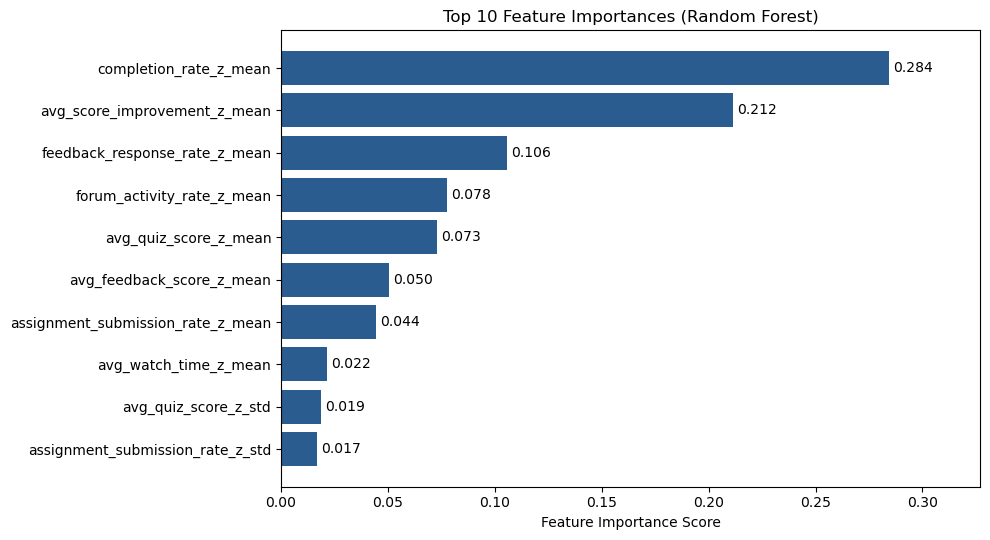

In [14]:
# Feature Importance
best.fit(X, y)
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values(ascending=False)
display(imp.head(10).round(3))

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(imp.head(10).index[::-1], imp.head(10).values[::-1], color="#2b5c8f")
ax.bar_label(bars, labels=[f"{v:.3f}" for v in imp.head(10).values[::-1]], padding=3)  # numbers on bars
ax.set_xlim(0, imp.max() * 1.15)   # room for the labels
ax.set_xlabel("Feature Importance Score")
ax.set_title("Top 10 Feature Importances (Random Forest)")
plt.tight_layout(); plt.show()

In [15]:
# Importance by pillar
pillars = {"Outcomes": ["completion_rate", "avg_score_improvement", "avg_quiz_score"],
           "Engagement": ["avg_watch_time", "assignment_submission_rate", "forum_activity_rate"],
           "Feedback": ["avg_feedback_score", "feedback_response_rate"]}
for p, cols in pillars.items():
    print(p, round(imp[[c for c in imp.index if any(c.startswith(x) for x in cols)]].sum(), 3))

Outcomes 0.613
Engagement 0.188
Feedback 0.187


## Key Drivers of Instructor Effectiveness

**Feature importance (Random Forest, top 10):** `completion_rate_z_mean` (0.284), `avg_score_improvement_z_mean` (0.212), `feedback_response_rate_z_mean` (0.106), `forum_activity_rate_z_mean` (0.078), `avg_quiz_score_z_mean` (0.073), `avg_feedback_score_z_mean` (0.050), `assignment_submission_rate_z_mean` (0.044), `avg_watch_time_z_mean` (0.022), `avg_quiz_score_z_std` (0.019) and `assignment_submission_rate_z_std` (0.017).

**Importance by pillar:** Outcomes 0.613, Engagement 0.188, Feedback 0.187 (the remaining 0.012 is `n_batches_feat`).

### Interpretation

- **Learner outcomes dominate.** Completion and score improvement together carry about 50% of the model's importance, and the Outcomes pillar carries 61%. Instructors whose learners finish courses and improve their scores are the ones consistently placed in the higher tiers.
- **Importance does not simply mirror the IES weights.** The model is not re-deriving the formula. For example, `feedback_response_rate` (9% of IES weight) ranks 3rd, while `avg_feedback_score` (21% of IES weight) ranks 6th, and `forum_activity_rate` (the lowest IES weight) outranks `avg_watch_time`. This is the expected result of predicting the tier from *different batches* than those that defined it.
- **Feedback response rate is informative.** Instructors whose learners respond to feedback surveys more consistently also tend to be rated higher overall. This may reflect a more engaged cohort, which is a signal of cohort engagement, not necessarily teaching quality.
- **Consistency features matter little.** Standard-deviation features each have importance below 0.02, so with only a few batches per instructor the *average* level of performance is far more informative than its variability.

### Caveats

- Random Forest importances show what the model *uses*, not what *causes* effectiveness.
- Impurity-based importances can favour continuous features and split credit between correlated ones (e.g., completion and score improvement), so the ranking among close features (e.g., 0.078 vs 0.073) is not reliable.
- With 120 instructors, small differences in importance are noise.

# Mandatory Analysis Questions and Answers:
_ _ _ _ _ _ _ _ _ _ _

### 1. Which features most influenced instructor effectiveness, and why?
-> The most influential features are **`completion_rate_z_mean` (importance 0.284)** and **`avg_score_improvement_z_mean` (0.212)**, followed by `feedback_response_rate_z_mean` (0.106). By pillar, Outcomes account for 61% of the importance, Engagement 19% and Feedback 19%. Reasons: i) Completion and score improvement are the clearest outcomes of good teaching, and they are measured consistently across an instructor's batches, so one set of batches predicts how another set will rank. ii) The importances do not mirror the IES weights (e.g., `avg_feedback_score` has 21% of the IES weight but only 0.050 importance), because the tier was built from different batches than the model's features. This shows the model learned real patterns and is not just reproducing the formula.

---

### 2. Which variables could be misleading or confounded?
-> There are a few such variables: i) `dropout_rate` and `completion_rate` are almost perfectly negatively correlated (r = -0.95), so `dropout_rate` was removed. ii) **Course difficulty** is a confounder: instructors teaching hard courses naturally see lower completion and quiz scores. This was handled by z-scoring every metric within its course, but differences in learner background within a course remain uncontrolled. iii) `completion_rate` dominates the importances (0.284), but means from instructors with few batches are easily distorted by one unusual batch. iv) `forum_activity_rate_z_mean` (0.078) and `assignment_submission_rate_z_mean` (0.044) reflect learner intent as much as instruction quality. v) `feedback_response_rate_z_mean` ranks 3rd (0.106), but it likely reflects cohort engagement, not teaching quality. vi) `avg_feedback_score` carries subjective biases (topic popularity, grade leniency) that do not always match actual learning growth.


---

### 3. How could this model fail in real-world usage?
**->** The model could fail in the following ways:

**i)** **Gaming of metrics.** Since `completion_rate_z_mean` is the most influential feature (importance 0.284), instructors might artificially lower assignment difficulty so that struggling students can complete the course. Completion metrics would then be inflated and higher-tier placement secured without any real improvement in teaching.

**ii)** **Data drift.** Changes in student demographics, platform UI updates, or altered curriculum formats over time can invalidate the historical feature distributions the model was trained on.

**iii)** **Unreliable estimates for instructors with few batches.** Some instructors have as few as 6 batches in total (about 3 in the feature half), so their means and standard deviations are noisy and prone to large fluctuations. Shrinkage (K = 5) stabilises the tier label, but the features of such instructors remain uncertain.

**iv)** **Small sample and noisy labels.** The model is trained on only 120 instructors, and the tier is computed from just half of each instructor's batches. Cross-validated accuracy is about 0.86 ± 0.06, and 16 of 120 instructors were misclassified, so predictions near a tier boundary are unreliable.

**v)** **Relative tiers.** Tiers are percentile-based (25/50/25), so someone is always labelled "Low" even if all instructors perform well. The tier tells us the *rank* of an instructor, not their absolute quality.

**vi)** **Over-reliance on static historical averages.** Aggregated metrics treat past performance as permanent, and the model cannot detect sudden burnout, personal emergencies or rapid instructional improvement in real time.

---

### 4. What additional data would you want to improve this analysis?
**->** I would like to add the following:

**i)** **Raw text from student feedback comments**, analysed with NLP, to reveal specific teaching behaviours (e.g., clarity, empathy, pace) that numerical ratings obscure.

**ii)** **Longitudinal instructor trajectories.** Multi-quarter historical data would track performance trends over time instead of evaluating static aggregates, which helps separate temporary dips from long-term trends.

**iii)** **Course and learner context.** Metrics are already normalised within each course, but richer information on course level (introductory vs. advanced), subject matter, learner background and whether enrollment was mandatory or voluntary would allow fairer comparisons between instructors.

**iv)** **Qualitative evaluations** from senior faculty or curriculum directors, plus peer reviews, to balance student-driven metrics with expert assessment. These could also serve as an independent ground truth, instead of a tier derived from the same metrics.

**v)** **More batches per instructor**, so that tiers and features can be built from larger samples, with a true held-out period (e.g., predicting next quarter's tier from this quarter's data).

---

### 5. Should this model be used for instructor performance evaluation? Why or why not?
**->** No. This model should **not** be used for instructor performance evaluation or as an automated decision-maker. It should be used only as a **decision-support tool**, for the following reasons:

**i)** **It overlooks qualitative context.** Algorithmic evaluation cannot see that an instructor stepped in to manage a struggling cohort, piloted a new unproven curriculum, or teaches unusually complex subjects. Such an instructor could be unfairly flagged as "Low", especially since the model's main driver is completion rate. Metrics are normalised within each course, but this cannot remove every difference in learner background.

**ii)** **It is not accurate enough for high-stakes use.** Even with cross-validated accuracy of about 0.86, 16 of 120 instructors were misclassified. Using such tiers for promotion, salary or termination would produce wrong decisions for a meaningful number of people.

**iii)** **Incentive distortion.** If tiers directly influence salary, promotion or contract renewal, instructors are incentivised to lower academic standards, pass struggling students or simplify exams to artificially boost `completion_rate`. The metric would then stop measuring what it was meant to measure.

**iv)** **The tiers are relative and partly arbitrary.** The percentile cut-offs force a 25/50/25 distribution, and the IES weights are a judgement call (though tiers were stable under alternative weights, with 92% to 98% of instructors keeping the same tier).

**Recommended use:** as an **early-warning system**. It can help administrative teams quickly identify which instructors might benefit from additional teaching resources, mentorship or peer review before student outcomes suffer. Any flagged instructor should then be reviewed by a human who has the qualitative context.